# Experimental: relative humidity, equivalent potential temperature and 3-D wind in height, from model-level data

**This is an experimental example.** It is based on the Metview gallery example [Cross Section 3D Wind in Height for Model Level Data](https://metview.readthedocs.io/en/latest/gen_files/gallery/cross_section_wind3d_height_ml_orog.html), and uses earthkit-geo, [earthkit-meteo](https://earthkit-meteo.readthedocs.io), xarray and earthkit-plots. The horizontal part (the line, its tangent vectors and the regridding onto the line) uses the new `earthkit.geo.polyline` module, whose interface may still change. **All the computations use earthkit-meteo**: the pressure and the height of the hybrid model levels, the vertical velocity in m/s, the relative humidity, the equivalent potential temperature and the interpolation to height levels.

The plot shows, along a line from (37.1°N, 104.4°W) to (37.3°N, 89.5°W), in height above sea level from 0 to 10 km, three layers:

- the **relative humidity** (RH) in % as green shading from 40 to 110 %;
- the **equivalent potential temperature** (EPT) as brown contour lines every 2 K. The multiples of 8 K are solid, thicker and labelled, the other lines are dashed;
- the **3-D wind** as arrows in the vertical plane. The horizontal component is the wind component along the line, positive in the direction of travel, i.e. eastwards. The vertical component is the vertical velocity `w` in m/s, positive upwards, multiplied by 100 so that it is visible.

The orography is the charcoal area at the bottom.

The notebook reads a GRIB file. It contains forecast data of the run 2022-04-29 12 UTC, step 12 h, on the hybrid model levels 60 to 137 of the 137-level IFS. 

**Differences from the Metview example.** The results are very close, but not identical:

- The heights come from `earthkit.meteo.vertical` and are *geometric* heights above sea level. Metview divides the geopotential by 9.81 (a geopotential height). The difference is under about 0.2 %, i.e. about 15 m at 10 km.
- The equivalent potential temperature is computed with `earthkit.meteo.thermo.ept_from_specific_humidity` (the `"ifs"` method). Metview's `eqpott_m` may use a slightly different formula, so the EPT contours can differ a little.
- Here the fields are regridded onto the line first, and the nonlinear diagnostics (pressure, `w`, RH, EPT and height) are computed afterwards on the line. Metview computes the diagnostics on the grid first and then makes the cross-section.

To make this notebook work [earthkit-data](https://earthkit-data.readthedocs.io), [earthkit-meteo](https://earthkit-meteo.readthedocs.io), [earthkit-plots](https://earthkit-plots.readthedocs.io) and xarray have to be installed.

## Imports

In [1]:
import earthkit.data as ekd
import earthkit.geo as ekg
import earthkit.plots as ekp
import numpy as np
import xarray as xr
from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import polyline_normals, sample_polyline
from earthkit.meteo import thermo, vertical, wind

## Load the data

The file contains the temperature `t`, the specific humidity `q`, the wind components `u` and `v` and the pressure velocity `w` (omega, in Pa/s) on the model levels 60 to 137, the logarithm of the surface pressure `lnsp` and the surface geopotential `z`, which have one field each. It is a GRIB2 file on a regular 0.5° latitude-longitude grid over the area 20–45°N, 120–80°W. Here is a short listing of the first fields.

In [2]:
ds = ekd.from_source("sample", "xs_ml_wind_orog.grib").to_fieldlist()
print(len(ds), "fields")
ds[:6].ls()

xs_ml_wind_orog.grib:   0%|          | 0.00/3.59M [00:00<?, ?B/s]

392 fields


,parameter.variable,time.valid_datetime,time.base_datetime,time.step,vertical.level,vertical.level_type,ensemble.member,geography.grid_type
0,t,2022-04-30,2022-04-29 12:00:00,0 days 12:00:00,60,hybrid,None,regular_ll
1,q,2022-04-30,2022-04-29 12:00:00,0 days 12:00:00,60,hybrid,None,regular_ll
2,u,2022-04-30,2022-04-29 12:00:00,0 days 12:00:00,60,hybrid,None,regular_ll
3,v,2022-04-30,2022-04-29 12:00:00,0 days 12:00:00,60,hybrid,None,regular_ll
4,w,2022-04-30,2022-04-29 12:00:00,0 days 12:00:00,60,hybrid,None,regular_ll
5,t,2022-04-30,2022-04-29 12:00:00,0 days 12:00:00,61,hybrid,None,regular_ll


## Select the fields

We select `t`, `q`, `u`, `v` and `w` (omega), which give 78 fields each, `lnsp`, which gives one field, and the surface geopotential `z`, which gives one field (it is from the analysis, step 0). The cell asserts that the model levels of each variable are 60, 61, …, 137, in ascending order, from the upper troposphere to the surface. This is the order which the earthkit-meteo functions need.

In [3]:
t = ds.sel({"parameter.variable": "t"})
q = ds.sel({"parameter.variable": "q"})
u = ds.sel({"parameter.variable": "u"})
v = ds.sel({"parameter.variable": "v"})
omega = ds.sel({"parameter.variable": "w"})  # pressure velocity (Pa/s), called "w" in the GRIB file
lnsp = ds.sel({"parameter.variable": "lnsp"})
zs = ds.sel({"parameter.variable": "z"})  # surface geopotential

for name, fl in [("t", t), ("q", q), ("u", u), ("v", v), ("omega", omega)]:
    model_levels = [f.get("vertical.level") for f in fl]
    assert model_levels == list(range(60, 138)), f"{name}: the model levels must be 60..137 in ascending order"
    print(f"{name}: {len(fl)} fields, model levels {model_levels[0]}..{model_levels[-1]}")
print("lnsp:", len(lnsp), "field; surface z:", len(zs), "field")

t: 78 fields, model levels 60..137
q: 78 fields, model levels 60..137
u: 78 fields, model levels 60..137
v: 78 fields, model levels 60..137
omega: 78 fields, model levels 60..137
lnsp: 1 field; surface z: 1 field


## Hybrid level coefficients

The pressure on a hybrid level is `p = A + B * sp`, where `A` and `B` are the coefficients of the half-levels of the model. They are stored in the GRIB messages, in the `pv` key, as 138 values of `A` followed by 138 values of `B` (137 levels have 138 half-levels). The cell takes them from the GRIB and checks that they agree with the standard 137-level IFS coefficients of `vertical.hybrid_level_parameters(137)`. The values differ slightly through rounding, so the check uses a tolerance (`rtol=1e-5`, `atol=1e-7`), because the default tolerance is too strict. The coefficients of the GRIB message are the ones used for the computations.

The data only has the levels 60 to 137, i.e. a partial column from the model level 60 to the ground. The functions of earthkit-meteo work on such a column if `A` and `B` are limited to the half-levels which enclose these levels. The level `k` lies between the half-levels `k-1` (its upper boundary) and `k` (its lower boundary), so the levels 60 to 137 need the half-levels 59 to 137, which are `A[59:]` and `B[59:]` (79 values). The cell below makes these sub-ranges.

In [4]:
pv = np.asarray(u[0].get("metadata.pv"))
A, B = pv[:138], pv[138:]
A_ref, B_ref = vertical.hybrid_level_parameters(137)
np.testing.assert_allclose(A, A_ref, rtol=1e-5, atol=1e-7)
np.testing.assert_allclose(B, B_ref, rtol=1e-5, atol=1e-7)
print("A:", A.shape, "B:", B.shape, "- they agree with hybrid_level_parameters(137)")

# half-levels 59..137, which enclose the full levels 60..137
A_sub, B_sub = A[59:], B[59:]
print("A_sub:", A_sub.shape, "B_sub:", B_sub.shape)

A: (138,) B: (138,) - they agree with hybrid_level_parameters(137)
A_sub: (79,) B_sub: (79,)


## Define the line

[sample_polyline()](https://earthkit-geo.readthedocs.io) returns the latitudes and longitudes of 200 points along the line from (37.1°N, 104.4°W) to (37.3°N, 89.5°W), which is the line of the Metview example. We use `method="linear"`: the points are evenly spaced in latitude and longitude, i.e. they lie on a straight line in a plain latitude-longitude map, as in Metview. This is not the great circle, which is the default.

In [5]:
lats, lons = sample_polyline([37.1, 37.3], [-104.4, -89.5], n=200, method="linear")
print(lats.shape, (lats[0], lons[0]), (lats[-1], lons[-1]))

(200,) (np.float64(37.1), np.float64(-104.4)) (np.float64(37.3), np.float64(-89.5))


## Regrid onto the line

All the fields (78 levels of `t`, `q`, `u`, `v` and omega, `lnsp` and the surface geopotential) are regridded onto the 200 points of the line, which are given as an unstructured target grid. The default linear interpolation is used. The result is a fieldlist with one field of 200 values for each input field. MIR may print some `GridUnknownError` and `ECCODES` lines during this step for each of the 392 fields (e.g. about an unknown grid or an unstructured grid in a GRIB edition 1 message), they come from the C libraries and do not stop the regridding. The values are stacked into arrays with the shape (level, point).

In [6]:
out_grid = {"latitudes": lats.tolist(), "longitudes": lons.tolist()}


def on_line(fieldlist):
    return np.stack([f.values for f in ekg.regrid(fieldlist, out_grid=out_grid)])


T = on_line(t)  # (level, point)
Q = on_line(q)
U = on_line(u)
V = on_line(v)
OMEGA = on_line(omega)
LNSP = on_line(lnsp)[0]  # (point)
ZS = on_line(zs)[0]  # (point)
print(T.shape, Q.shape, U.shape, V.shape, OMEGA.shape, LNSP.shape, ZS.shape)
print("NaNs:", [int(np.isnan(x).sum()) for x in (T, Q, U, V, OMEGA, LNSP, ZS)])

(78, 200) (78, 200) (78, 200) (78, 200) (78, 200) (200,) (200,)
NaNs: [0, 0, 0, 0, 0, 0, 0]


## Surface pressure and orography

The surface pressure in Pa is the exponential of `lnsp`. The height of the ground above sea level, the orography, is the geometric height of the surface geopotential, computed with `vertical.geometric_height_from_geopotential()`.

In [7]:
sp = np.exp(LNSP)  # Pa, (point)
hs = vertical.geometric_height_from_geopotential(ZS)  # m, (point)
print(f"surface pressure: {sp.min() / 100:.1f} to {sp.max() / 100:.1f} hPa")
print(f"orography: {hs.min():.0f} to {hs.max():.0f} m")

surface pressure: 797.5 to 995.0 hPa
orography: 122 to 1934 m


## Pressure on the model levels

[pressure_on_hybrid_levels()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.vertical` computes the pressure at each of the 78 full model levels and each point of the line, from the surface pressure and the coefficients of the partial column. The result `P` has the shape (level, point) and is in Pa.

**Partial column check.** The pressure of a level only depends on the two half-levels which enclose it and on the surface pressure, so the partial column must give the same pressure as the full 137-level column, for the levels 60 to 137. The same holds for the `alpha` parameter of the layers, which is used for the heights. The cell computes the pressure and `alpha` on the full column and on the partial one, and asserts that they agree.

In [8]:
P = vertical.pressure_on_hybrid_levels(sp, A_sub, B_sub, output="full")  # Pa, (level, point)
print(P.shape)
print(f"pressure of the top level (60): {P[0].min() / 100:.1f} to {P[0].max() / 100:.1f} hPa")
print(f"pressure of the lowest level (137): {P[-1].min() / 100:.1f} to {P[-1].max() / 100:.1f} hPa")

# partial column vs the full column (rows 59: are the levels 60..137)
P_full, alpha_full = vertical.pressure_on_hybrid_levels(sp, A, B, output=("full", "alpha"))
P_part, alpha_part = vertical.pressure_on_hybrid_levels(sp, A_sub, B_sub, output=("full", "alpha"))
np.testing.assert_allclose(P_part, P_full[59:], rtol=1e-12)
np.testing.assert_allclose(alpha_part, alpha_full[59:], rtol=1e-12)
print("pressure and alpha of the partial column agree with the full column")

(78, 200)
pressure of the top level (60): 98.4 to 98.4 hPa
pressure of the lowest level (137): 796.5 to 993.8 hPa
pressure and alpha of the partial column agree with the full column


## Vertical velocity, relative humidity and equivalent potential temperature

These three computations use the temperature, the specific humidity and the pressure on the model levels, all with the shape (level, point):

- [w_from_omega()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.wind` converts the pressure velocity omega (Pa/s, positive downwards) to the vertical velocity in m/s, positive upwards;
- [relative_humidity_from_specific_humidity()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.thermo` gives the relative humidity in %;
- [ept_from_specific_humidity()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.thermo` gives the equivalent potential temperature in K.

In [9]:
w = wind.w_from_omega(OMEGA, T, P)  # m/s, positive up
rh = thermo.relative_humidity_from_specific_humidity(T, Q, P)  # %
ept = thermo.ept_from_specific_humidity(T, Q, P)  # K
print(f"w from {w.min():.2f} to {w.max():.2f} m/s")
print(f"rh from {rh.min():.1f} to {rh.max():.1f} %")
print(f"ept from {ept.min():.1f} to {ept.max():.1f} K")

w from -0.22 to 0.45 m/s
rh from 3.2 to 107.3 %
ept from 313.8 to 411.6 K


## Height of the model levels

[height_on_hybrid_levels()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.vertical` computes the geometric height of the full model levels above sea level (`h_type="geometric"`, `h_reference="sea"`), from the temperature, the humidity, the surface geopotential, the surface pressure and the coefficients. It integrates the hydrostatic equation from the ground upwards, so it also works for the partial column. The cell checks that the height decreases with the model level number (the level 137 is the lowest one), and that the lowest level is about 10 m above the ground.

In [10]:
# m, (level, point)
H = vertical.height_on_hybrid_levels(T, Q, ZS, sp, A_sub, B_sub, h_type="geometric", h_reference="sea")
print(H.shape)
print(f"height of the top level (60): {H[0].min():.0f} to {H[0].max():.0f} m")
height_above_ground = H[-1] - hs
print(f"lowest level above the ground: {height_above_ground.min():.1f} to {height_above_ground.max():.1f} m")
assert np.all(np.diff(H, axis=0) < 0), "the height must decrease with the model level number"
assert np.all((height_above_ground > 5) & (height_above_ground < 20)), "the lowest level is about 10 m above ground"

(78, 200)
height of the top level (60): 16429 to 16454 m
lowest level above the ground: 10.1 to 10.6 m


## Wind component along the line

The along-line component is the scalar product of the horizontal wind with the unit tangent vector of the line, which points in the direction of travel. The tangent is the left normal vector of [polyline_normals()](https://earthkit-geo.readthedocs.io) rotated back by 90° clockwise: `t_east = north_n` and `t_north = -east_n`, as in the notebook [cross_section_wind_parallel.ipynb](cross_section_wind_parallel.ipynb). The line goes towards the east, so the component is positive eastwards. The cell checks that the tangent has unit length and is perpendicular to the normal.

In [11]:
east_n, north_n = polyline_normals(lats, lons, method="linear")
t_east = north_n
t_north = -east_n
assert np.allclose(np.hypot(t_east, t_north), 1.0), "the tangent must have unit length"
assert np.allclose(t_east * east_n + t_north * north_n, 0.0), "the tangent must be perpendicular to the normal"
print(f"tangent at the first point: ({t_east[0]:.3f}, {t_north[0]:.3f})")

wp = U * t_east + V * t_north  # m/s, positive in the direction of travel (eastwards), (level, point)
print(f"wp from {wp.min():.1f} to {wp.max():.1f} m/s")

tangent at the first point: (1.000, 0.017)
wp from -4.6 to 42.3 m/s


## Interpolate to height levels

The model levels follow the ground, so their height differs from point to point. [interpolate_hybrid_to_height_levels()](https://earthkit-meteo.readthedocs.io) of `earthkit.meteo.vertical` interpolates `rh`, `ept`, `wp` and `w` linearly to the fixed heights 0, 100, …, 10000 m above sea level (101 levels, as in Metview), at each point of the line. The result has the shape (height, point).

Between the lowest model level (about 10 m above the ground) and the ground the interpolation would be an extrapolation. As in Metview (a "constant" extrapolation), we give the values of the lowest model level as the values at the ground (`aux_bottom_data` and `aux_bottom_h`), so that the layer is filled with them. The heights below the ground remain `NaN`, and they are hidden by the orography.

In [12]:
target_h = np.arange(0, 10001, 100)  # m above sea level


def to_height(x):
    return vertical.interpolate_hybrid_to_height_levels(
        x,
        target_h,
        T,
        Q,
        ZS,
        sp,
        A_sub,
        B_sub,
        h_type="geometric",
        h_reference="sea",
        interpolation="linear",
        aux_bottom_data=x[-1],  # the lowest model level, used down to the ground
        aux_bottom_h=hs,
    )


rh_h = to_height(rh)
ept_h = to_height(ept)
wp_h = to_height(wp)
w_h = to_height(w)
print(rh_h.shape, ept_h.shape, wp_h.shape, w_h.shape)

(101, 200) (101, 200) (101, 200) (101, 200)


## Check the missing values

The missing values must be only below the ground. The cell prints the number of `NaN` below and above the ground for the four fields (a target height is above the ground if it is not lower than the orography `hs`), and asserts that there are none above the ground and that all the values below the ground are `NaN`. It also prints the ranges of the interpolated values above the ground.

In [13]:
below_ground = target_h[:, np.newaxis] < hs[np.newaxis, :]

for name, x in [("rh", rh_h), ("ept", ept_h), ("wp", wp_h), ("w", w_h)]:
    nan = np.isnan(x)
    print(f"{name}: NaNs below the ground: {int((nan & below_ground).sum())} of {int(below_ground.sum())} values")
    print(f"{name}: NaNs above the ground: {int((nan & ~below_ground).sum())} of {int((~below_ground).sum())} values")
    assert not nan[~below_ground].any(), f"{name}: there must be no NaN above the ground"
    assert nan[below_ground].all(), f"{name}: all the values below the ground must be NaN"
    print(f"{name}: from {x[~below_ground].min():.2f} to {x[~below_ground].max():.2f}")

rh: NaNs below the ground: 1334 of 1334 values
rh: NaNs above the ground: 0 of 18866 values
rh: from 4.78 to 100.30
ept: NaNs below the ground: 1334 of 1334 values
ept: NaNs above the ground: 0 of 18866 values
ept: from 313.80 to 339.18
wp: NaNs below the ground: 1334 of 1334 values
wp: NaNs above the ground: 0 of 18866 values
wp: from -4.16 to 41.83
w: NaNs below the ground: 1334 of 1334 values
w: NaNs above the ground: 0 of 18866 values
w: from -0.22 to 0.45


## Build an Xarray Dataset

We build a Dataset with the relative humidity `rh` (%), the equivalent potential temperature `ept` (K), the along-line wind `wp` (m/s) and the vertical velocity `w` (m/s) on the dimensions `height` (m) and `distance` (km), and the orography (m) on `distance` only. The distance is the cumulative length of the path along the sampled points. It is the sum of the haversine distances (in metres, so we divide by 1000) between consecutive points. The latitudes and longitudes of the points are stored as auxiliary coordinates of `distance`.

In [14]:
# cumulative path length along the sampled points, in km
step_length = np.array([
    haversine_distance((lats[i], lons[i]), (lats[i + 1], lons[i + 1])) for i in range(len(lats) - 1)
])
distance = np.concatenate([[0.0], np.cumsum(step_length)]) / 1000

dims = ("height", "distance")
xs = xr.Dataset(
    {
        "rh": (dims, rh_h, {"units": "%", "long_name": "Relative humidity"}),
        "ept": (dims, ept_h, {"units": "K", "long_name": "Equivalent potential temperature"}),
        "wp": (dims, wp_h, {"units": "m s-1", "long_name": "Wind parallel component"}),
        "w": (dims, w_h, {"units": "m s-1", "long_name": "Vertical velocity"}),
        "orography": (("distance",), hs, {"units": "m", "long_name": "Orography"}),
    },
    coords={
        "height": ("height", target_h, {"units": "m"}),
        "distance": ("distance", distance, {"units": "km"}),
        "latitude": ("distance", lats, {"units": "degrees_north"}),
        "longitude": ("distance", lons, {"units": "degrees_east"}),
    },
)
xs

<xarray.Dataset> Size: 654kB
Dimensions:    (height: 101, distance: 200)
Coordinates:
  * height     (height) int64 808B 0 100 200 300 400 ... 9700 9800 9900 10000
  * distance   (distance) float64 2kB 0.0 6.642 13.28 ... 1.313e+03 1.32e+03
    latitude   (distance) float64 2kB 37.1 37.1 37.1 37.1 ... 37.3 37.3 37.3
    longitude  (distance) float64 2kB -104.4 -104.3 -104.3 ... -89.57 -89.5
Data variables:
    rh         (height, distance) float64 162kB nan nan nan ... 42.23 40.81
    ept        (height, distance) float64 162kB nan nan nan ... 328.5 328.4
    wp         (height, distance) float64 162kB nan nan nan ... 7.661 7.788
    w          (height, distance) float64 162kB nan nan ... 0.004598 0.008899
    orography  (distance) float64 2kB 1.934e+03 1.915e+03 ... 129.1 122.5

## Plot the cross-section

We use a non-map earthkit-plots `Subplot`, as in the Metview example, which has no map.

- **Relative humidity:** filled contours from 40 to 110 % every 10 % with the matplotlib colour map `Greens`, which is close to the Metview palette (light to dark green). The colour bar is added with the `legend()` method of the figure. Values below 40 % are not shaded.
- **Equivalent potential temperature:** contour lines every 2 K. The lines which are not a multiple of 8 K are dashed and brown. The multiples of 8 K (320 K, 328 K, …) are solid, thicker, brown and labelled.
- **Wind arrows:** drawn with the `quiver()` method of the matplotlib axis `.ax`, because the `quiver()` method of earthkit-plots is made for geographical data: it treats the x values as longitudes, and wraps the values above 180 into -180..180, so it moves the arrows when x is the distance along the line in km. The horizontal component of each arrow is the along-line wind `wp`, and the vertical component is the vertical velocity multiplied by 100, `100 * w`. With `angles="uv"` the arrows are drawn in screen space, so a rising air points up on the screen. To keep the plot readable only every 3rd height level and every 5th point of the line is used. The arrows are navy. A key arrow of 30 m/s shows the scale, and its label says that the vertical part is multiplied by 100.
- **Orography:** added with `fill_between()` and drawn in charcoal from the surface height down to 0 m, on top of the other layers.
- **Axes:** the vertical axis goes from 0 to 10000 m with the label "Height ASL (m)", and there is no grid. The 8 ticks of the horizontal axis are where the line crosses the longitudes 104°W, 102°W, …, 90°W, as in Metview. Their distance and latitude are found by linear interpolation along the sampled points. The labels have the latitude with up to 2 decimals (a trailing zero is dropped) and the longitude in whole degrees.

Two details need explanation:

- `resample=False` is needed for `contourf()` and `contour()`. By default earthkit-plots resamples the data onto a 1000 × 1000 latitude-longitude grid, which is wrong for a distance-height section.
- The key arrow, the axis limits, the ticks, the labels and the removal of the grid lines are matplotlib calls on the axis `.ax` of the subplot, because earthkit-plots has no dedicated option for them.

['37.11°N/104°W', '37.13°N/102°W', '37.16°N/100°W', '37.19°N/98°W', '37.21°N/96°W', '37.24°N/94°W', '37.27°N/92°W', '37.29°N/90°W']


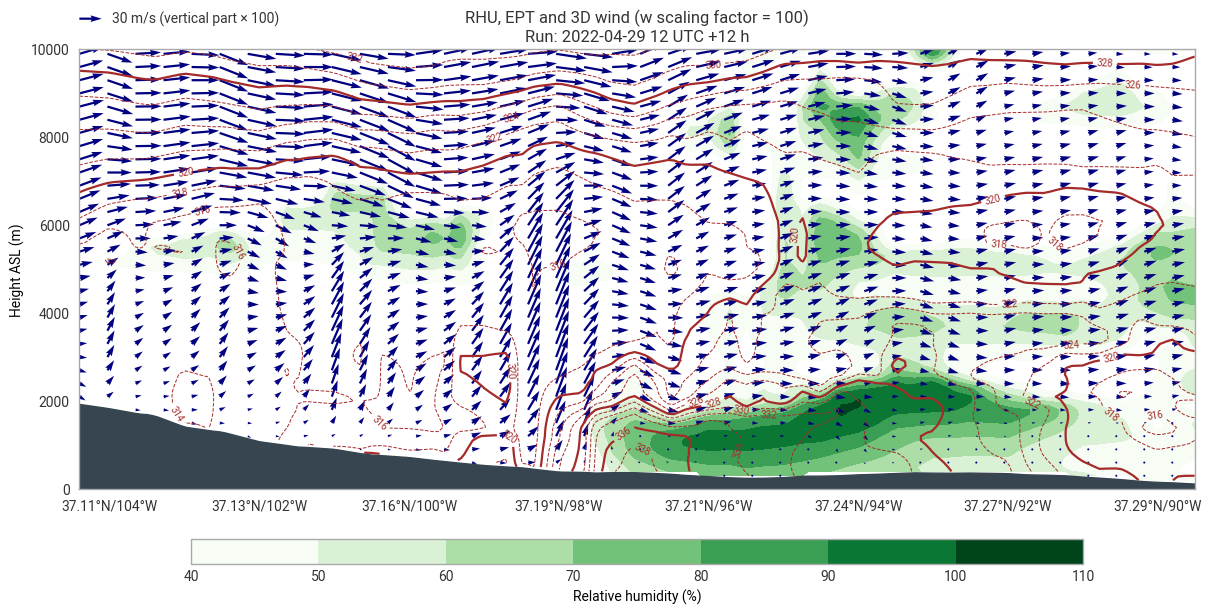

In [15]:
rh_levels = list(range(40, 111, 10))
ept_min, ept_max = np.nanmin(xs["ept"].values), np.nanmax(xs["ept"].values)
ept_levels = list(range(int(np.floor(ept_min / 2) * 2), int(np.ceil(ept_max / 2) * 2) + 1, 2))
ept_dashed = [lev for lev in ept_levels if lev % 8 != 0]
ept_solid = [lev for lev in ept_levels if lev % 8 == 0]

chart = ekp.Subplot(figsize=(12, 6))

# relative humidity: green shading
chart.contourf(
    xs["rh"],
    x="distance",
    y="height",
    style=ekp.styles.Style(levels=rh_levels, colors="Greens", ticks=rh_levels),
    resample=False,
)
chart.figure.legend(label="Relative humidity (%)")

# equivalent potential temperature: dashed lines every 2 K, solid labelled lines every 8 K
chart.contour(
    xs["ept"],
    x="distance",
    y="height",
    style=ekp.styles.Contour(levels=ept_dashed, colors="brown", linewidths=0.7, linestyles="dashed", legend_style=None),
    resample=False,
)
chart.contour(
    xs["ept"],
    x="distance",
    y="height",
    style=ekp.styles.Contour(
        levels=ept_solid,
        colors="brown",
        linewidths=1.6,
        labels=True,
        label_kwargs={"label_fmt": "%d"},
        legend_style=None,
    ),
    resample=False,
)

# 3-D wind: along-line wind and 100 * vertical velocity, every 3rd level and every 5th point
rows, cols = slice(None, None, 3), slice(None, None, 5)
X, Y = np.meshgrid(xs["distance"].values[cols], xs["height"].values[rows])
U_arrow = xs["wp"].values[rows, cols]  # m/s, along the line (eastwards)
V_arrow = 100 * xs["w"].values[rows, cols]  # m/s, vertical velocity times 100, up

ax = chart.ax
arrows = ax.quiver(X, Y, U_arrow, V_arrow, color="navy", angles="uv", scale=1500, width=0.002)
ax.quiverkey(arrows, 0.02, 1.07, 30, "30 m/s (vertical part × 100)", coordinates="axes", labelpos="E")

# orography: charcoal polygon from the surface height down to 0 m, drawn on top
chart.fill_between(xs["orography"], 0, x=xs["distance"], color="#36454f", alpha=1)

# 8 ticks where the line crosses the longitudes 104W ... 90W (lons increase along the line)
tick_lons = np.arange(-104, -89, 2)
tick_distance = np.interp(tick_lons, lons, distance)
tick_lats = np.interp(tick_lons, lons, lats)
tick_labels = [f"{round(lat, 2):g}°N/{abs(lon)}°W" for lat, lon in zip(tick_lats, tick_lons)]
print(tick_labels)

ax.set_xlim(distance[0], distance[-1])
ax.set_ylim(0, 10000)
ax.set_xticks(tick_distance)
ax.set_xticklabels(tick_labels)
ax.grid(False)  # no grid lines over the arrows, as in Metview
ax.set_ylabel("Height ASL (m)")
ax.set_title("RHU, EPT and 3D wind (w scaling factor = 100)\nRun: 2022-04-29 12 UTC +12 h")

chart.show()